In [1]:
import numba
import numpy as np
from profdata import load_profdata
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

/home/keke/.pixi/envs/py/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
@numba.jit(nopython=True, boundscheck=False)
def sim_matrix_impl(act_hash, res):
    N, K = act_hash.shape
    for i in range(N):
        for j in range(N):
            A = (act_hash[i] * act_hash[j]).sum()
            B = (act_hash[i] + act_hash[j]).sum()
            res[i, j] = 1.0 * A / (B - A + 1)

def sim_matrix(act_hash):
    N, K = act_hash.shape
    act_hash = act_hash.astype(np.int32)
    res = np.empty((N, N), dtype=np.float32)
    sim_matrix_impl(act_hash, res)
    return res

In [7]:
data = load_profdata('pgo-data/boom_m_1.T1.prof.bin')

In [8]:
act_hash = data.threads[0].act_hash
act_hash

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 1, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(2328, 4096), dtype=uint8)

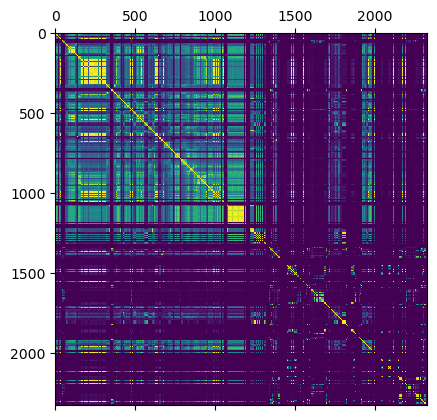

In [9]:
iou = sim_matrix(act_hash[:, :2048])
plt.matshow(iou, cmap='viridis')

In [10]:
np.save('prof-method-stat/binsample-method.npy', iou)

In [11]:
ground_truth = np.load('prof-method-stat/ground-truth.npy')
np.abs(ground_truth - iou).mean()

np.float64(0.07967944609927767)